# Simple model: viewer rating
Predict TMDB `vote_average` with ordinary linear regression. Report MAE, RMSE, and R² against predicting the training mean rating.

Use **9 predictors instead of 39**, read from the existing feature-engineering output. The original baseline is fixed. Optional Section 5 compares six compact feature presets without changing estimator settings or the success threshold. Run from this folder with `ds6001`; no CSVs or model files are written.

## 1. Load data and choose nine predictors
Use runtime, director experience, smoothed mean rating of observed earlier director films and the number of rated earlier titles, certification, release month, sequel status, English-language status, and a director-history availability flag.

Four numeric predictors, two categorical predictors, and three binary indicators keep the model small. Counts are already `log1p` transformed in the source table. Both current-movie targets and identifiers are excluded from predictors.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LinearRegression
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

movies = pd.read_csv("../../data/model_data.csv", parse_dates=["release_date"])
movies = movies.sort_values("release_date", kind="stable").reset_index(drop=True)
NUMERIC_FEATURES = ["runtime", "dir_prior_films_log1p", "dir_prior_rating_smoothed", "dir_prior_rated_films_log1p"]
CATEGORICAL_FEATURES = ["us_certification", "release_month"]
BINARY_FEATURES = ["is_sequel", "is_english", "dir_no_rating_history"]
FEATURE_COLUMNS = NUMERIC_FEATURES + CATEGORICAL_FEATURES + BINARY_FEATURES
TARGET = "vote_average"

assert len(FEATURE_COLUMNS) == 9
assert not {"success", "vote_average", "tmdb_id", "imdb_id", "title_tmdb", "release_date", "budget", "revenue"} & set(FEATURE_COLUMNS)
assert movies["tmdb_id"].is_unique and movies["release_date"].notna().all()
assert movies[BINARY_FEATURES].isin([0, 1]).all().all()
X = movies[FEATURE_COLUMNS].copy()
for column in CATEGORICAL_FEATURES:
    X[column] = X[column].map(lambda value: str(value) if pd.notna(value) else np.nan)
y = movies[TARGET].copy()
assert y.notna().all()
print(f"{len(movies):,} movies | 9 predictors | Target: {TARGET}")
display(pd.DataFrame({
    "Predictor": FEATURE_COLUMNS,
    "Role": ["Numeric"] * 4 + ["Categorical"] * 2 + ["Binary"] * 3,
}))
assert y.between(0, 10).all()

6,919 movies | 9 predictors | Target: vote_average


,Predictor,Role
0,runtime,Numeric
1,dir_prior_films_log1p,Numeric
2,dir_prior_rating_smoothed,Numeric
3,dir_prior_rated_films_log1p,Numeric
4,us_certification,Categorical
5,release_month,Categorical
6,is_sequel,Binary
7,is_english,Binary
8,dir_no_rating_history,Binary


## 2. Split chronologically
Use the same earlier approximately 80% for training and later 20% for testing as the other models. Equal release dates stay together.

In [2]:
cutoff = movies.loc[int(len(movies) * 0.8), "release_date"]
train = movies["release_date"].lt(cutoff)
test = ~train
X_train, X_test = X.loc[train], X.loc[test]
y_train, y_test = y.loc[train], y.loc[test]
assert movies.loc[train, "release_date"].max() < movies.loc[test, "release_date"].min()
assert set(movies.loc[train, "tmdb_id"]).isdisjoint(movies.loc[test, "tmdb_id"])
display(pd.DataFrame([
    ["Training", len(y_train), movies.loc[train, "release_date"].min(), movies.loc[train, "release_date"].max()],
    ["Test", len(y_test), movies.loc[test, "release_date"].min(), movies.loc[test, "release_date"].max()],
], columns=["Split", "Movies", "First release", "Last release"]))

,Split,Movies,First release,Last release
0,Training,5535,1990-01-12,2017-11-17
1,Test,1384,2017-11-18,2025-12-25


## 3. Fit Linear regression
Fit numeric medians/scaling and categorical imputation/one-hot encoding using training data only. Binary indicators pass through unchanged. All settings are fixed for this simple baseline.

In [3]:
preprocessor = ColumnTransformer([
    ("numeric", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ]), NUMERIC_FEATURES),
    ("categorical", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False)),
    ]), CATEGORICAL_FEATURES),
    ("binary", "passthrough", BINARY_FEATURES),
])
model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LinearRegression()),
])
model.fit(X_train, y_train)
train_prediction = model.predict(X_train)
test_prediction = model.predict(X_test)
baseline = DummyRegressor(strategy="mean")
baseline.fit(np.zeros((len(y_train), 1)), y_train)
baseline_prediction = baseline.predict(np.zeros((len(y_test), 1)))

## 4. Evaluate
Compare the training and later-test results with a simple baseline, then inspect the first ten test predictions.

,Model,Split,MAE,RMSE,R2
0,Training mean baseline,Test,0.6197,0.7729,-0.1766
1,Simple linear regression,Training,0.5301,0.6815,0.2341
2,Simple linear regression,Test,0.5430,0.6871,0.0702


,title_tmdb,vote_average,predicted_rating
5535,Revenge,6.500,6.969
5536,Darkest Hour,7.400,6.731
5537,"Three Billboards Outside Ebbing, Missouri",8.051,6.644
5538,The Shape of Water,7.200,6.721
5539,Wonder Wheel,6.400,6.216
5540,Molly's Game,7.155,7.032
5541,"I, Tonya",7.464,6.574
5542,Ferdinand,7.209,6.584
5543,Star Wars: The Last Jedi,6.731,6.915
5544,Loving Pablo,6.300,7.139


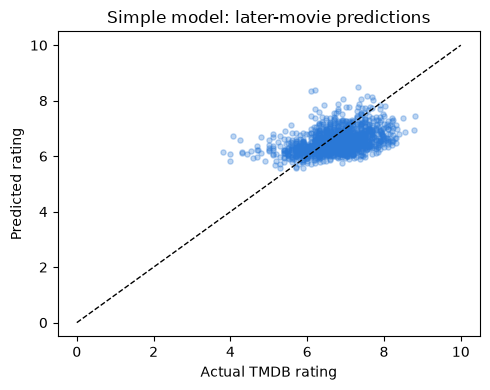

In [4]:
def score(name, split, actual, predicted):
    return {
        "Model": name, "Split": split,
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(mean_squared_error(actual, predicted)),
        "R2": r2_score(actual, predicted),
    }
results = pd.DataFrame([
    score("Training mean baseline", "Test", y_test, baseline_prediction),
    score("Simple linear regression", "Training", y_train, train_prediction),
    score("Simple linear regression", "Test", y_test, test_prediction),
])
display(results.round(4))
examples = movies.loc[test, ["title_tmdb", "vote_average"]].copy()
examples["predicted_rating"] = test_prediction
display(examples.head(10).round(3))
plt.figure(figsize=(5, 4))
plt.scatter(y_test, test_prediction, alpha=0.3, s=14, color="#2a78d6")
plt.plot([0, 10], [0, 10], "k--", linewidth=1)
plt.xlabel("Actual TMDB rating")
plt.ylabel("Predicted rating")
plt.title("Simple model: later-movie predictions")
plt.tight_layout()
plt.show()

## 5. Compare small feature sets
Try six named presets, each with **5–10 predictors**. Keep the same estimator settings and success threshold (0.5); only predictors change. Three expanding chronological validation folds stay entirely inside the original training period, with fresh preprocessing fitted in every fold.

Select the preset with the lowest **mean validation MAE**.

Refit the validation-selected preset on all training movies and compare it with the original nine-feature model on the same later test rows. Do not choose a preset from its test score. This is exploratory comparison on already-inspected data, not independent confirmation of improvement. You can edit `feature_versions` to define another small preset before rerunning.

In [5]:
from sklearn.model_selection import TimeSeriesSplit

basics = ["runtime", "us_certification", "release_month", "is_sequel", "is_english"]
feature_versions = {
    "Movie basics": basics,
    "+ Director experience": basics + ["dir_prior_films_log1p"],
    "Original director history": FEATURE_COLUMNS,
    "Actor/company/franchise": basics + [
        "lead_actor_films_5yr_backfilled_log1p", "backfill_unavailable",
        "company_films_5yr_log1p", "franchise_prior_films_log1p",
    ],
    "Basics + four genres": basics + ["genre_drama", "genre_comedy", "genre_action", "genre_horror"],
    "Compact mix": basics + [
        "dir_prior_rating_smoothed", "dir_prior_rated_films_log1p", "dir_no_rating_history",
        "lead_actor_films_5yr_backfilled_log1p", "company_films_5yr_log1p",
    ],
}
assert all(len(columns) <= 10 and len(columns) == len(set(columns)) for columns in feature_versions.values())
comparison_features = list(dict.fromkeys(column for columns in feature_versions.values() for column in columns))
assert not {"success", "vote_average", "tmdb_id", "imdb_id", "title_tmdb", "release_date", "budget", "revenue"} & set(comparison_features)
comparison_X = movies[comparison_features].copy()
for column in CATEGORICAL_FEATURES:
    comparison_X[column] = comparison_X[column].map(lambda value: str(value) if pd.notna(value) else np.nan)
comparison_binary = BINARY_FEATURES + ["backfill_unavailable"] + [column for column in movies if column.startswith("genre_")]

# Same model and preprocessing rules for every preset.
def make_feature_model(columns):
    numeric = [column for column in columns if column not in CATEGORICAL_FEATURES + comparison_binary]
    categorical = [column for column in CATEGORICAL_FEATURES if column in columns]
    binary = [column for column in columns if column in comparison_binary]
    return Pipeline([
        ("preprocessor", ColumnTransformer([
            ("numeric", Pipeline([
                ("imputer", SimpleImputer(strategy="median")),
                ("scaler", StandardScaler()),
            ]), numeric),
            ("categorical", Pipeline([
                ("imputer", SimpleImputer(strategy="most_frequent")),
                ("encoder", OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False)),
            ]), categorical),
            ("binary", "passthrough", binary),
        ])),
        ("model", LinearRegression()),
    ])

training_dates = movies.loc[train, "release_date"]
unique_dates = np.sort(training_dates.unique())
feature_splits = []
for earlier, later in TimeSeriesSplit(n_splits=3).split(unique_dates):
    fit_rows = training_dates.index[training_dates.isin(unique_dates[earlier])]
    validation_rows = training_dates.index[training_dates.isin(unique_dates[later])]
    assert movies.loc[fit_rows, "release_date"].max() < movies.loc[validation_rows, "release_date"].min()
    assert set(fit_rows).union(validation_rows).issubset(set(y_train.index))
    feature_splits.append((fit_rows, validation_rows))

fold_results = []
for version, columns in feature_versions.items():
    for fold, (fit_rows, validation_rows) in enumerate(feature_splits, 1):
        candidate = make_feature_model(columns)
        candidate.fit(comparison_X.loc[fit_rows], y.loc[fit_rows])
        predicted = candidate.predict(comparison_X.loc[validation_rows])
        metrics = score(version, "Validation", y.loc[validation_rows], predicted)
        fold_results.append({"Version": version, "Fold": fold, "Predictors": len(columns), **{key: metrics[key] for key in ["MAE", "RMSE", "R2"]}})
feature_fold_results = pd.DataFrame(fold_results)
feature_comparison = feature_fold_results.groupby("Version", sort=False).agg(
    Predictors=("Predictors", "first"), MAE=("MAE", "mean"),
    MAE_std=("MAE", "std"), RMSE=("RMSE", "mean"), R2=("R2", "mean"),
)
selected_version = feature_comparison["MAE"].idxmin()
with pd.option_context("display.max_columns", None):
    display(feature_comparison.round(4))
print("Selected using training-period validation:", selected_version)
selected_columns = feature_versions[selected_version]
print("Selected predictors:", selected_columns)

feature_selected_model = make_feature_model(selected_columns)
feature_selected_model.fit(comparison_X.loc[train], y_train)
selected_prediction = feature_selected_model.predict(comparison_X.loc[test])
selected_test_result = score("Validation-selected simple model", "Test", y_test, selected_prediction)
comparison_test_results = pd.concat([results.loc[results["Split"].eq("Test")], pd.DataFrame([selected_test_result])], ignore_index=True)
display(comparison_test_results.round(4))
print("The original model above is retained. Lower test errors or higher classification scores are not guaranteed by validation selection.")
assert len(feature_fold_results) == 18


,Predictors,MAE,MAE_std,RMSE,R2
Version,,,,,
Movie basics,5,0.5424,0.0077,0.6988,0.1864
+ Director experience,6,0.5417,0.0092,0.6984,0.1876
Original director history,9,0.5382,0.0142,0.6927,0.2009
Actor/company/franchise,9,0.5421,0.0064,0.6995,0.1849
Basics + four genres,9,0.5249,0.0066,0.6766,0.2373
Compact mix,10,0.5369,0.0144,0.6922,0.2020


Selected using training-period validation: Basics + four genres
Selected predictors: ['runtime', 'us_certification', 'release_month', 'is_sequel', 'is_english', 'genre_drama', 'genre_comedy', 'genre_action', 'genre_horror']


,Model,Split,MAE,RMSE,R2
0,Training mean baseline,Test,0.6197,0.7729,-0.1766
1,Simple linear regression,Test,0.5430,0.6871,0.0702
2,Validation-selected simple model,Test,0.5587,0.7038,0.0246


The original model above is retained. Lower test errors or higher classification scores are not guaranteed by validation selection.


## Interpretation
Lower MAE/RMSE is better; MAE is measured in rating points. Higher R² is better. Compare with the mean-rating baseline first. Predictions are not clipped to 0–10. A simpler model is easier to explain but may not predict as well as the larger models.

History covers observed earlier films and uses retrospective snapshots, not a complete director filmography or verified historical ratings/outcomes. Earlier-year histories update through time, representing rolling predictions. Results describe the financially eligible cohort and the already-inspected later period, so they are exploratory. Keep the same evaluation rows when comparing simple and detailed models.